In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit

DATA_PATH = "../data/processed/sleep_epochs_corrected.csv"

df = pd.read_csv(DATA_PATH)

# Identify metadata and target columns.
metadata_cols = [
    "subject_id",
    "recording_id",
    "epoch_index",
    "start_sec",
    "end_sec",
    "stage",
]

feature_cols = [col for col in df.columns if col not in metadata_cols]

X = df[feature_cols]
y = df["stage"]
groups = df["subject_id"]

print("Dataset shape:", df.shape)
print("Number of features:", len(feature_cols))
print("\nClass distribution:")
print(y.value_counts())
print("\nClass proportions:")
print((y.value_counts(normalize=True) * 100).round(2))
print("Features:", feature_cols)

Dataset shape: (414961, 38)
Number of features: 32

Class distribution:
stage
W      285433
N2      69132
REM     25835
N1      21522
N3      13039
Name: count, dtype: int64

Class proportions:
stage
W      68.79
N2     16.66
REM     6.23
N1      5.19
N3      3.14
Name: proportion, dtype: float64
Features: ['EEG Fpz-Cz_mean', 'EEG Fpz-Cz_std', 'EEG Fpz-Cz_rms', 'EEG Fpz-Cz_ptp', 'EEG Fpz-Cz_delta_power', 'EEG Fpz-Cz_theta_power', 'EEG Fpz-Cz_alpha_power', 'EEG Fpz-Cz_sigma_power', 'EEG Fpz-Cz_beta_power', 'EEG Fpz-Cz_delta_relative', 'EEG Fpz-Cz_theta_relative', 'EEG Fpz-Cz_alpha_relative', 'EEG Fpz-Cz_sigma_relative', 'EEG Fpz-Cz_beta_relative', 'EEG Pz-Oz_mean', 'EEG Pz-Oz_std', 'EEG Pz-Oz_rms', 'EEG Pz-Oz_ptp', 'EEG Pz-Oz_delta_power', 'EEG Pz-Oz_theta_power', 'EEG Pz-Oz_alpha_power', 'EEG Pz-Oz_sigma_power', 'EEG Pz-Oz_beta_power', 'EEG Pz-Oz_delta_relative', 'EEG Pz-Oz_theta_relative', 'EEG Pz-Oz_alpha_relative', 'EEG Pz-Oz_sigma_relative', 'EEG Pz-Oz_beta_relative', 'EOG horizont

In [2]:
# Splitting by subject and not epochs
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_subjects = set(groups.iloc[train_idx])
test_subjects = set(groups.iloc[test_idx])

print("Training epochs:", len(X_train))
print("Testing epochs:", len(X_test))
print("Training subjects:", len(train_subjects))
print("Testing subjects:", len(test_subjects))
print("Subject overlap:", train_subjects & test_subjects)

assert train_subjects.isdisjoint(test_subjects)

Training epochs: 327570
Testing epochs: 87391
Training subjects: 62
Testing subjects: 16
Subject overlap: set()


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

print("Dummy accuracy:", round(accuracy_score(y_test, dummy_pred), 4))
print(
    "Dummy balanced accuracy:",
    round(balanced_accuracy_score(y_test, dummy_pred), 4),
)
print("Dummy macro F1:", round(f1_score(
    y_test, dummy_pred, average="macro", zero_division=0
), 4))

print("\nPer-stage report:")
print(classification_report(
    y_test,
    dummy_pred,
    labels=["W", "N1", "N2", "N3", "REM"],
    zero_division=0,
))

Dummy accuracy: 0.689
Dummy balanced accuracy: 0.2
Dummy macro F1: 0.1632

Per-stage report:
              precision    recall  f1-score   support

           W       0.69      1.00      0.82     60213
          N1       0.00      0.00      0.00      4551
          N2       0.00      0.00      0.00     14679
          N3       0.00      0.00      0.00      2716
         REM       0.00      0.00      0.00      5232

    accuracy                           0.69     87391
   macro avg       0.14      0.20      0.16     87391
weighted avg       0.47      0.69      0.56     87391



In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42,
    )),
])

logreg.fit(X_train, y_train)

logreg_pred = logreg.predict(X_test)

print("Training complete.")

Training complete.


In [11]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * len(name))
    print(f"Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
    print(
        f"Balanced accuracy: "
        f"{balanced_accuracy_score(y_true, y_pred):.4f}"
    )
    print(
        f"Macro F1:          "
        f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}"
    )

evaluate_model("Dummy baseline", y_test, dummy_pred)
evaluate_model("Logistic Regression", y_test, logreg_pred)

print("\nPer-stage classification report:")
print(classification_report(
    y_test,
    logreg_pred,
    labels=["W", "N1", "N2", "N3", "REM"],
    zero_division=0,
))


Dummy baseline
--------------
Accuracy:          0.6890
Balanced accuracy: 0.2000
Macro F1:          0.1632

Logistic Regression
-------------------
Accuracy:          0.8781
Balanced accuracy: 0.6551
Macro F1:          0.6647

Per-stage classification report:
              precision    recall  f1-score   support

           W       0.95      0.97      0.96     60213
          N1       0.25      0.11      0.15      4551
          N2       0.78      0.87      0.82     14679
          N3       0.88      0.71      0.79      2716
         REM       0.59      0.62      0.61      5232

    accuracy                           0.88     87391
   macro avg       0.69      0.66      0.66     87391
weighted avg       0.86      0.88      0.87     87391



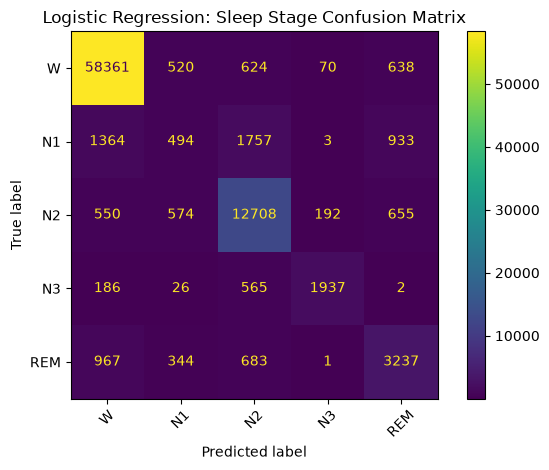

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

stage_order = ["W", "N1", "N2", "N3", "REM"]

cm = confusion_matrix(
    y_test,
    logreg_pred,
    labels=stage_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_order,
)

disp.plot(values_format="d", xticks_rotation=45)
plt.title("Logistic Regression: Sleep Stage Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
balanced_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])

balanced_logreg.fit(X_train, y_train)
balanced_pred = balanced_logreg.predict(X_test)

evaluate_model(
    "Class-weighted Logistic Regression",
    y_test,
    balanced_pred,
)

print(classification_report(
    y_test,
    balanced_pred,
    labels=["W", "N1", "N2", "N3", "REM"],
    zero_division=0,
))


Class-weighted Logistic Regression
----------------------------------
Accuracy:          0.7980
Balanced accuracy: 0.7180
Macro F1:          0.6327
              precision    recall  f1-score   support

           W       0.99      0.85      0.91     60213
          N1       0.21      0.42      0.28      4551
          N2       0.84      0.72      0.78     14679
          N3       0.57      0.86      0.69      2716
         REM       0.39      0.74      0.51      5232

    accuracy                           0.80     87391
   macro avg       0.60      0.72      0.63     87391
weighted avg       0.87      0.80      0.83     87391



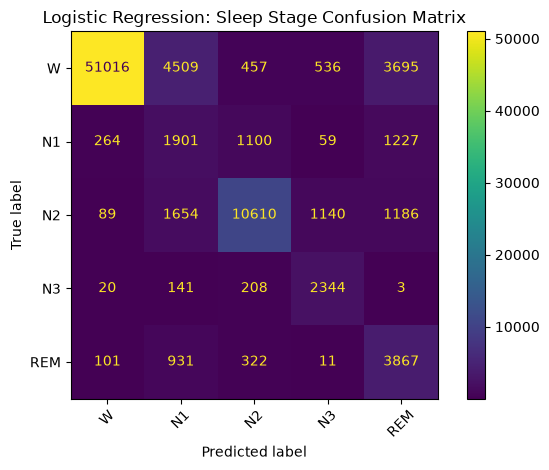

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

stage_order = ["W", "N1", "N2", "N3", "REM"]

cm = confusion_matrix(
    y_test,
    balanced_pred,
    labels=stage_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_order,
)

disp.plot(values_format="d", xticks_rotation=45)
plt.title("Logistic Regression: Sleep Stage Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

stage_order = ["W", "N1", "N2", "N3", "REM"]

# Mean feature values for each sleep stage.
stage_means = (
    df.groupby("stage")[feature_cols]
      .mean()
      .reindex(stage_order)
)

display(stage_means.T)

stage,W,N1,N2,N3,REM
EEG Fpz-Cz_mean,7.989052e-08,2.433244e-07,6.217570e-08,-3.450786e-07,-3.643675e-08
EEG Fpz-Cz_std,2.673427e-05,1.275837e-05,1.478501e-05,2.758425e-05,1.214737e-05
EEG Fpz-Cz_rms,2.688109e-05,1.297228e-05,1.498790e-05,2.775642e-05,1.243649e-05
EEG Fpz-Cz_ptp,1.987599e-04,1.012440e-04,1.144164e-04,1.712942e-04,9.451607e-05
EEG Fpz-Cz_delta_power,3.789545e-10,6.869424e-11,1.253142e-10,5.284874e-10,5.616549e-11
EEG Fpz-Cz_theta_power,4.009059e-11,1.034410e-11,1.565334e-11,2.763331e-11,1.081881e-11
EEG Fpz-Cz_alpha_power,1.572408e-11,6.667805e-12,6.960357e-12,9.284908e-12,4.642118e-12
EEG Fpz-Cz_sigma_power,1.064666e-11,3.312363e-12,5.037681e-12,4.713075e-12,2.003329e-12
EEG Fpz-Cz_beta_power,3.854231e-11,6.428741e-12,2.972513e-12,2.462454e-12,3.905149e-12
EEG Fpz-Cz_delta_relative,7.554980e-01,6.695733e-01,7.836035e-01,9.134113e-01,6.957261e-01


In [18]:
relative_power_cols = [
    col for col in feature_cols
    if "relative" in col
]

display(
    df.groupby("stage")[relative_power_cols]
      .mean()
      .reindex(stage_order)
      .T
)

stage,W,N1,N2,N3,REM
EEG Fpz-Cz_delta_relative,0.755498,0.669573,0.783604,0.913411,0.695726
EEG Fpz-Cz_theta_relative,0.088628,0.122294,0.107450,0.053643,0.147502
EEG Fpz-Cz_alpha_relative,0.042032,0.085094,0.049267,0.018617,0.067735
EEG Fpz-Cz_sigma_relative,0.025421,0.040306,0.036352,0.009345,0.029328
EEG Fpz-Cz_beta_relative,0.088420,0.082732,0.023327,0.004984,0.059710
EEG Pz-Oz_delta_relative,0.469248,0.594924,0.721267,0.857530,0.621156
EEG Pz-Oz_theta_relative,0.130732,0.178917,0.159618,0.097387,0.192448
EEG Pz-Oz_alpha_relative,0.121667,0.130522,0.061402,0.027076,0.106443
EEG Pz-Oz_sigma_relative,0.069509,0.037660,0.035175,0.011455,0.033573
EEG Pz-Oz_beta_relative,0.208844,0.057977,0.022538,0.006551,0.046380


In [19]:
import numpy as np
import pandas as pd

eeg_channels = ["EEG Fpz-Cz", "EEG Pz-Oz"]
bands = ["delta", "theta", "alpha", "sigma", "beta"]

relative_cols = [
    f"{channel}_{band}_relative"
    for channel in eeg_channels
    for band in bands
]

absolute_cols = [
    f"{channel}_{band}_power"
    for channel in eeg_channels
    for band in bands
]

# Check that the expected features exist.
missing = [
    col for col in relative_cols + absolute_cols
    if col not in df.columns
]
assert not missing, f"Missing features: {missing}"

# Check finite and valid values.
relative_values = df[relative_cols]
absolute_values = df[absolute_cols]

print("Non-finite relative power values:",
      (~np.isfinite(relative_values)).sum().sum())

print("Negative relative power values:",
      (relative_values < 0).sum().sum())

print("Relative power values above 1:",
      (relative_values > 1).sum().sum())

print("Non-finite absolute power values:",
      (~np.isfinite(absolute_values)).sum().sum())

print("Negative absolute power values:",
      (absolute_values < 0).sum().sum())

# These five bands collectively define your 0.5-30 Hz range.
for channel in eeg_channels:
    cols = [
        f"{channel}_{band}_relative"
        for band in bands
    ]
    power_sum = df[cols].sum(axis=1)

    print(f"\n{channel}: relative power sum")
    print(power_sum.describe(percentiles=[0.01, 0.5, 0.99]))

    print(
        "Rows whose sum differs from 1 by more than 0.001:",
        ((power_sum - 1).abs() > 0.001).sum()
    )

Non-finite relative power values: 0
Negative relative power values: 0
Relative power values above 1: 0
Non-finite absolute power values: 0
Negative absolute power values: 0

EEG Fpz-Cz: relative power sum
count    4.149610e+05
mean     1.000000e+00
std      2.254937e-16
min      1.000000e+00
1%       1.000000e+00
50%      1.000000e+00
99%      1.000000e+00
max      1.000000e+00
dtype: float64
Rows whose sum differs from 1 by more than 0.001: 0

EEG Pz-Oz: relative power sum
count    4.149610e+05
mean     1.000000e+00
std      2.174066e-16
min      1.000000e+00
1%       1.000000e+00
50%      1.000000e+00
99%      1.000000e+00
max      1.000000e+00
dtype: float64
Rows whose sum differs from 1 by more than 0.001: 0


stage
W      225220
N1      16971
N2      54453
N3      10323
REM     20603
Name: count, dtype: int64
stage
N1     2000
N2     2000
N3     2000
REM    2000
W      2000
Name: count, dtype: int64


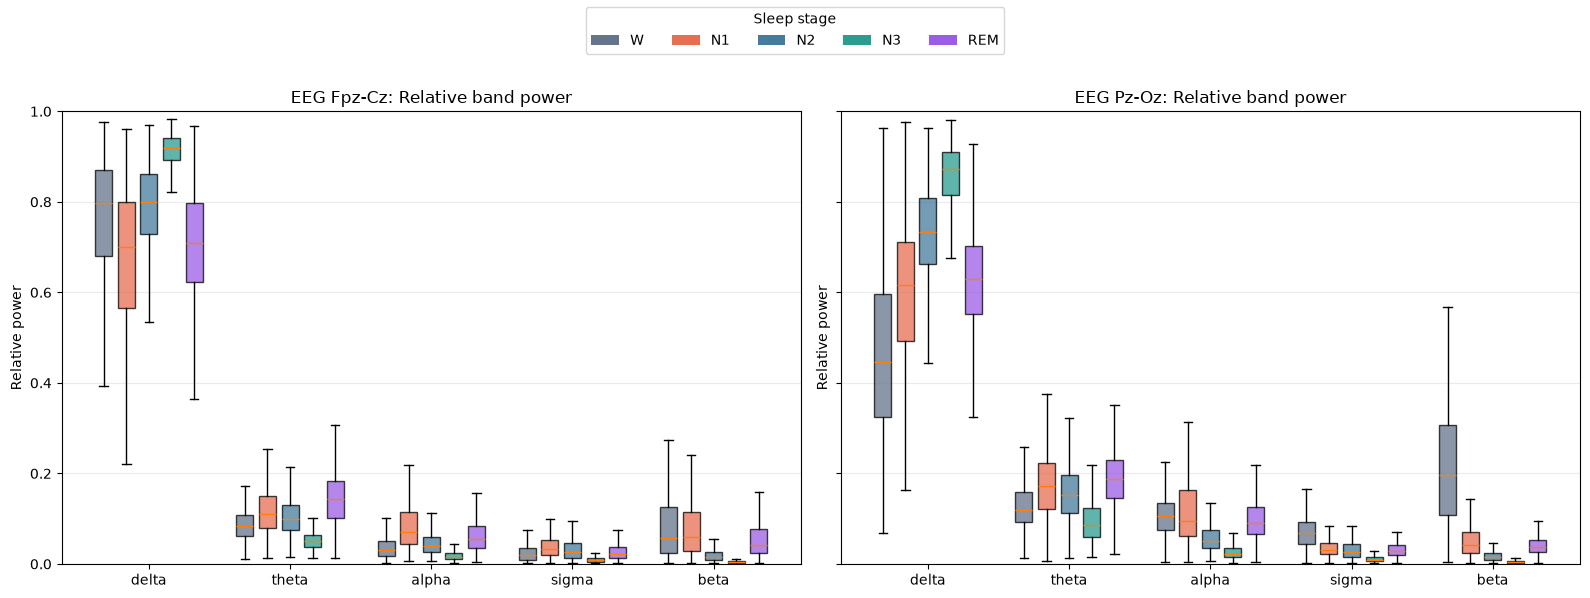

In [21]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Reuse the subject-level split already created.
train_df = df.iloc[train_idx].copy()

stage_order = ["W", "N1", "N2", "N3", "REM"]

# Check class labels.
print(train_df["stage"].value_counts().reindex(stage_order))

# Keep the plotting sample manageable and class-balanced.
plot_df = pd.concat(
    [
        group.sample(
            n=min(len(group), 2000),
            random_state=42,
        )
        for _, group in train_df.groupby("stage")
    ],
    ignore_index=True,
)

print(plot_df["stage"].value_counts())

stage_colors = {
    "W": "#64748b",
    "N1": "#e76f51",
    "N2": "#457b9d",
    "N3": "#2a9d8f",
    "REM": "#9b5de5",
}

offsets = np.linspace(-0.32, 0.32, len(stage_order))

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    sharey=True
)

for ax, channel in zip(axes, eeg_channels):
    all_data = []
    positions = []
    box_stages = []

    for band_idx, band in enumerate(bands):
        col = f"{channel}_{band}_relative"

        for stage_idx, stage in enumerate(stage_order):
            values = plot_df.loc[
                plot_df["stage"] == stage, col
            ].dropna().to_numpy()

            all_data.append(values)
            positions.append(band_idx + offsets[stage_idx])
            box_stages.append(stage)

    boxplot = ax.boxplot(
        all_data,
        positions=positions,
        widths=0.12,
        patch_artist=True,
        showfliers=False,
        manage_ticks=False,
    )

    for patch, stage in zip(boxplot["boxes"], box_stages):
        patch.set_facecolor(stage_colors[stage])
        patch.set_alpha(0.75)

    ax.set_xticks(range(len(bands)), bands)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Relative power")
    ax.set_title(f"{channel}: Relative band power")
    ax.grid(axis="y", alpha=0.25)

legend_items = [
    Patch(facecolor=stage_colors[s], label=s)
    for s in stage_order
]

fig.legend(
    handles=legend_items,
    title="Sleep stage",
    loc="upper center",
    ncol=5,
)

fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

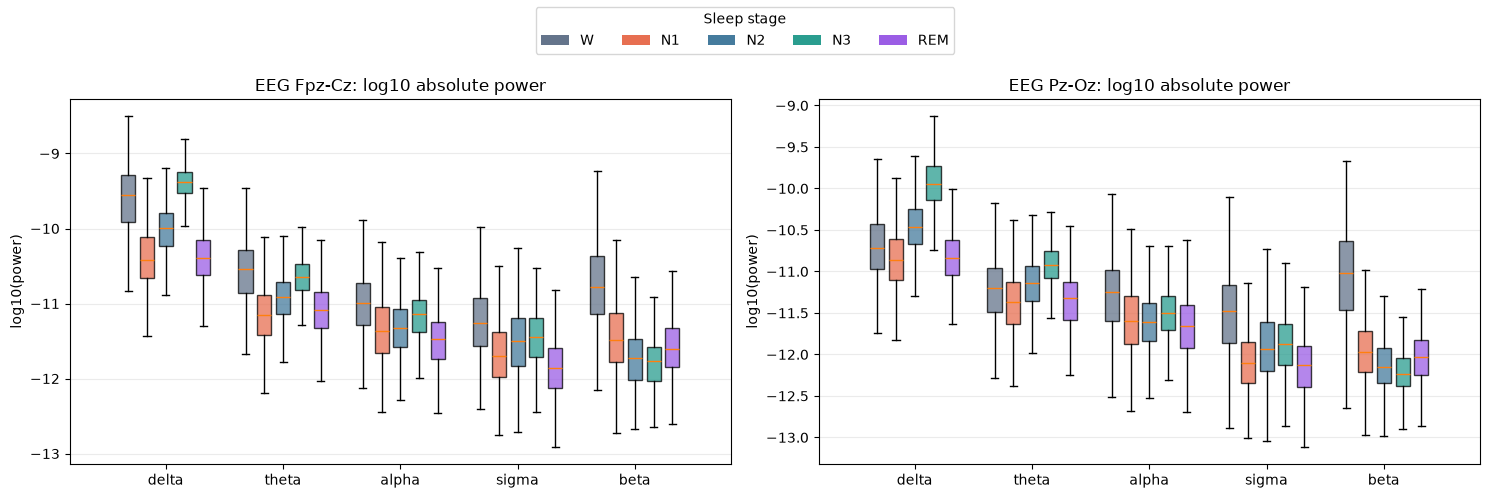

In [22]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, channel in zip(axes, eeg_channels):
    data = [
        np.log10(
            train_df.loc[
                train_df["stage"] == stage,
                f"{channel}_{band}_power"
            ].clip(lower=1e-30)
        ).sample(
            n=min(
                2000,
                (train_df["stage"] == stage).sum()
            ),
            random_state=42,
        )
        for band in bands
        for stage in stage_order
    ]

    positions = [
        band_idx + offset
        for band_idx in range(len(bands))
        for offset in offsets
    ]

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.12,
        patch_artist=True,
        showfliers=False,
    )

    for patch, stage in zip(
        bp["boxes"],
        stage_order * len(bands),
    ):
        patch.set_facecolor(stage_colors[stage])
        patch.set_alpha(0.75)

    ax.set_xticks(range(len(bands)), bands)
    ax.set_title(f"{channel}: log10 absolute power")
    ax.set_ylabel("log10(power)")
    ax.grid(axis="y", alpha=0.25)

fig.legend(
    handles=legend_items,
    title="Sleep stage",
    loc="upper center",
    ncol=5,
)

fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

In [35]:
import importlib
from src import features
from src.data_loader import load_recording
from src.preprocessing import build_epoch_table

importlib.reload(features)

raw = load_recording(PSG_PATH, HYPNOGRAM_PATH)
epoch_table = build_epoch_table(raw, epoch_seconds=30)

test_df = features.extract_recording_features(
    raw.copy(),
    epoch_table.iloc[:100].copy(),
    subject_id="SC400",
    recording_id="SC4001E0",
)

new_features = [
    col for col in test_df.columns
    if any(s in col for s in [
        "_theta_alpha_ratio",
        "_delta_beta_ratio",
        "_spectral_entropy",
    ])
]

print("Output shape:", test_df.shape)
print("New features:", new_features)

import numpy as np
assert len(new_features) == 6
assert np.isfinite(test_df[new_features].to_numpy()).all()

print("All six new features are present and finite.")
print(test_df[new_features].describe())

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Output shape: (100, 44)
New features: ['EEG Fpz-Cz_theta_alpha_ratio', 'EEG Fpz-Cz_delta_beta_ratio', 'EEG Fpz-Cz_spectral_entropy', 'EEG Pz-Oz_theta_alpha_ratio', 'EEG Pz-Oz_delta_beta_ratio', 'EEG Pz-Oz_spectral_entropy']
All six new features are present and finite.
       EEG Fpz-Cz_theta_alpha_ratio  EEG Fpz-Cz_delta_beta_ratio  \
count                    100.000000                   100.000000   
mean                       4.342953                    27.685075   
std                        1.561852                    14.441951   
min                        1.158244                     4.413845   
25%                        3.504621                    16.813836   
50%                        4.008587                    27.866144   
75%                        4.725804                    35.932546   
max                       11.740764                    81.366202   

       EEG Fpz-Cz_spectral_entropy  EEG Pz-Oz_theta_alpha_ratio  \
count                   100.000000                 

In [38]:
from pathlib import Path

CORRECTED_FEATURES_DIR = (
    project_root
    / "data"
    / "processed"
    / "recording_features_v2"
)

CORRECTED_FEATURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(CORRECTED_FEATURES_DIR)

d:\sscp\data\processed\recording_features_v2


In [40]:
subject_id = PSG_PATH.name[:5]
recording_id = PSG_PATH.stem.replace("-PSG", "")

In [45]:
from tqdm.auto import tqdm
import pandas as pd
from src.data_loader import load_recording
from src.preprocessing import build_epoch_table
from src import features

# Preserve the original feature files.
CORRECTED_FEATURES_DIR.mkdir(parents=True, exist_ok=True)

errors = []
processed = []
from pathlib import Path

CASSETTE_DIR = (
    project_root
    / "data"
    / "raw"
    / "sleep-cassette"
)

psg_files = sorted(CASSETTE_DIR.glob("*-PSG.edf"))
hypnogram_files = sorted(CASSETTE_DIR.glob("*-Hypnogram.edf"))

# Match recordings by subject + night identifier, first 6 characters.
hypnogram_map = {
    path.name[:6]: path
    for path in hypnogram_files
}

recording_pairs = [
    (PSG_PATH, hypnogram_map[PSG_PATH.name[:6]])
    for PSG_PATH in psg_files
    if PSG_PATH.name[:6] in hypnogram_map
]

print("PSG files:", len(psg_files))
print("Hypnogram files:", len(hypnogram_files))
print("Matched pairs:", len(recording_pairs))

assert len(recording_pairs) == 153, (
    f"Expected 153 matched recordings, found {len(recording_pairs)}"
)

for PSG_PATH, HYPNOGRAM_PATH in tqdm(recording_pairs):
    recording_id = PSG_PATH.stem.replace("-PSG", "")
    subject_id = PSG_PATH.name[:5]

    try:
        raw = load_recording(PSG_PATH, HYPNOGRAM_PATH)
        epoch_table = build_epoch_table(raw, epoch_seconds=30)

        feature_df = features.extract_recording_features(
            raw,
            epoch_table,
            subject_id=subject_id,
            recording_id=recording_id,
        )

        output_path = (
            CORRECTED_FEATURES_DIR
            / f"{recording_id}_features.csv"
        )
        feature_df.to_csv(output_path, index=False)

        processed.append({
            "recording_id": recording_id,
            "subject_id": subject_id,
            "rows": len(feature_df),
            "path": output_path,
        })

    except Exception as exc:
        errors.append((recording_id, repr(exc)))
        print(f"\nFAILED: {recording_id}: {exc}")

print("\nSuccessful recordings:", len(processed))
print("Failed recordings:", len(errors))
print("Total epochs:", sum(x["rows"] for x in processed))

PSG files: 153
Hypnogram files: 153
Matched pairs: 153


  0%|          | 0/153 [00:00<?, ?it/s]

d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:75: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:25: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
d:\sscp\src\data_loader.py:2


Successful recordings: 153
Failed recordings: 0
Total epochs: 414961


In [46]:
feature_files = sorted(
    CORRECTED_FEATURES_DIR.glob("*_features.csv")
)

assert not errors, f"Fix {len(errors)} failed recordings first."
assert len(feature_files) == 153, (
    f"Expected 153 recordings, found {len(feature_files)}"
)

dataset_v2 = pd.concat(
    [pd.read_csv(path) for path in feature_files],
    ignore_index=True,
)

metadata_cols = [
    "subject_id",
    "recording_id",
    "epoch_index",
    "start_sec",
    "end_sec",
    "stage",
]

feature_cols_v2 = [
    col for col in dataset_v2.columns
    if col not in metadata_cols
]

print("Dataset shape:", dataset_v2.shape)
print("Unique subjects:", dataset_v2["subject_id"].nunique())
print("Unique recordings:", dataset_v2["recording_id"].nunique())
print("Numerical features:", len(feature_cols_v2))
print("Missing values:", dataset_v2[feature_cols_v2].isna().sum().sum())
print(
    "Non-finite feature values:",
    (~np.isfinite(dataset_v2[feature_cols_v2])).sum().sum(),
)

assert dataset_v2["subject_id"].nunique() == 78
assert dataset_v2["recording_id"].nunique() == 153
assert len(feature_cols_v2) == 38
assert np.isfinite(dataset_v2[feature_cols_v2].to_numpy()).all()

DATASET_V2_PATH = (
    project_root / "data" / "processed" / "sleep_epochs_v2.csv"
)
dataset_v2.to_csv(DATASET_V2_PATH, index=False)

print("Saved:", DATASET_V2_PATH)

Dataset shape: (414961, 44)
Unique subjects: 78
Unique recordings: 153
Numerical features: 38
Missing values: 0
Non-finite feature values: 0
Saved: d:\sscp\data\processed\sleep_epochs_v2.csv


Training subjects: 62
Testing subjects: 16
Subject overlap: set()

Logistic Regression with new features
Accuracy: 0.8855
Balanced accuracy: 0.6688
Macro F1: 0.6821

               precision    recall  f1-score   support

           W       0.96      0.97      0.97     60213
          N1       0.28      0.15      0.20      4551
          N2       0.79      0.87      0.83     14679
          N3       0.89      0.70      0.79      2716
         REM       0.62      0.65      0.63      5232

    accuracy                           0.89     87391
   macro avg       0.71      0.67      0.68     87391
weighted avg       0.87      0.89      0.88     87391



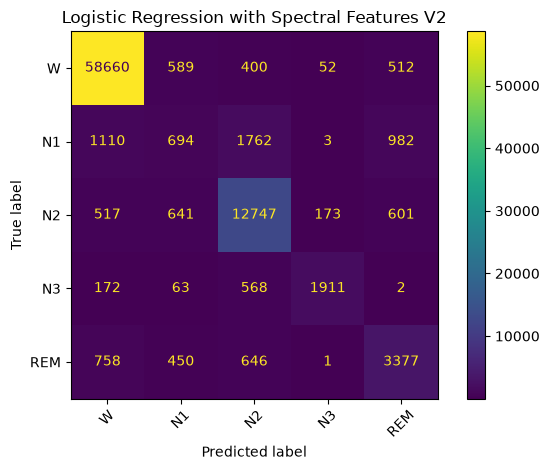

In [47]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import numpy as np

X_v2 = dataset_v2[feature_cols_v2]
y_v2 = dataset_v2["stage"]
groups_v2 = dataset_v2["subject_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx_v2, test_idx_v2 = next(
    splitter.split(X_v2, y_v2, groups=groups_v2)
)

X_train_v2 = X_v2.iloc[train_idx_v2]
X_test_v2 = X_v2.iloc[test_idx_v2]
y_train_v2 = y_v2.iloc[train_idx_v2]
y_test_v2 = y_v2.iloc[test_idx_v2]

train_subjects_v2 = set(groups_v2.iloc[train_idx_v2])
test_subjects_v2 = set(groups_v2.iloc[test_idx_v2])

assert train_subjects_v2.isdisjoint(test_subjects_v2)

print("Training subjects:", len(train_subjects_v2))
print("Testing subjects:", len(test_subjects_v2))
print("Subject overlap:", train_subjects_v2 & test_subjects_v2)

logreg_v2 = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42,
    )),
])

logreg_v2.fit(X_train_v2, y_train_v2)
pred_v2 = logreg_v2.predict(X_test_v2)

print("\nLogistic Regression with new features")
print("Accuracy:", round(accuracy_score(y_test_v2, pred_v2), 4))
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test_v2, pred_v2), 4),
)
print(
    "Macro F1:",
    round(f1_score(y_test_v2, pred_v2, average="macro"), 4),
)
print("\n", classification_report(
    y_test_v2,
    pred_v2,
    labels=["W", "N1", "N2", "N3", "REM"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test_v2,
    pred_v2,
    labels=["W", "N1", "N2", "N3", "REM"],
    xticks_rotation=45,
    values_format="d",
)
plt.title("Logistic Regression with Spectral Features V2")
plt.tight_layout()
plt.show()

In [48]:
import numpy as np

assert "raw" in globals(), "Load the PSG recording first."
assert "epoch_table" in globals(), "Build the epoch table first."

print("EEG channels:", [ch for ch in raw.ch_names if ch.startswith("EEG")])
print("Sampling frequency:", raw.info["sfreq"])
print("Epochs available:", len(epoch_table))
print("Stages:", epoch_table["stage"].value_counts())

EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0
Epochs available: 2810
Stages: stage
W      1954
N2      400
REM     179
N3      156
N1      121
Name: count, dtype: int64


In [49]:
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d


def detect_spindles_in_epoch(
    signal,
    sfreq,
    threshold_sd=1.5,
    min_duration=0.5,
    max_duration=2.0,
    merge_gap=0.1,
):
    """
    Experimental spindle-candidate detector for one EEG epoch.

    Returns candidate event intervals, filtered signal, smoothed
    amplitude envelope, and detection threshold.
    """
    signal = np.asarray(signal, dtype=float)

    if signal.ndim != 1 or len(signal) < 10:
        raise ValueError("signal must be a non-empty 1D array.")

    if not np.isfinite(signal).all():
        raise ValueError("signal contains non-finite values.")

    # Spindle-frequency band.
    sos = butter(
        4,
        [11, 16],
        btype="bandpass",
        fs=sfreq,
        output="sos",
    )

    filtered = sosfiltfilt(sos, signal)

    # Amplitude envelope of the filtered oscillation.
    envelope = np.abs(hilbert(filtered))

    # Smooth over approximately 100 ms.
    smooth_samples = max(1, int(round(0.1 * sfreq)))
    envelope = uniform_filter1d(
        envelope,
        size=smooth_samples,
    )

    # Initial heuristic threshold, estimated within this epoch.
    threshold = (
        envelope.mean()
        + threshold_sd * envelope.std()
    )

    active = envelope > threshold

    # Bridge short gaps between adjacent candidate bursts.
    max_gap_samples = int(round(merge_gap * sfreq))
    active_indices = np.flatnonzero(active)

    events = []

    if len(active_indices):
        groups = np.split(
            active_indices,
            np.where(np.diff(active_indices) > max_gap_samples + 1)[0] + 1,
        )

        for group in groups:
            start = int(group[0])
            end = int(group[-1]) + 1
            duration = (end - start) / sfreq

            if min_duration <= duration <= max_duration:
                events.append({
                    "start_sec": start / sfreq,
                    "end_sec": end / sfreq,
                    "duration_sec": duration,
                    "peak_envelope": float(envelope[start:end].max()),
                })

    return events, filtered, envelope, threshold

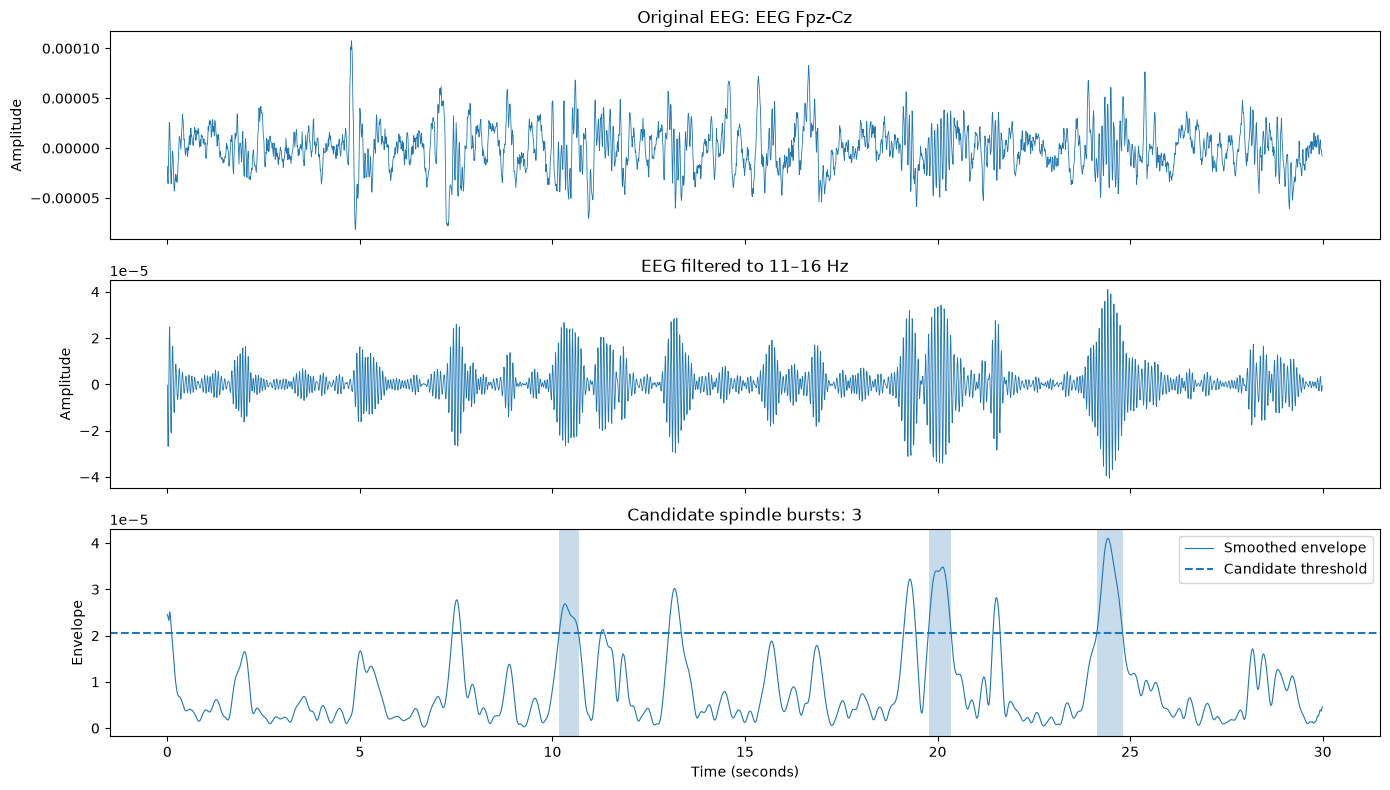

Stage: N2
Candidate spindle count: 3
   start_sec  end_sec  duration_sec  peak_envelope
0      10.18    10.68          0.50       0.000027
1      19.77    20.36          0.59       0.000035
2      24.14    24.81          0.67       0.000041


In [50]:
# Pick an N2 epoch from the current recording.
n2_rows = epoch_table[epoch_table["stage"] == "N2"]

if n2_rows.empty:
    raise ValueError("No N2 epochs found in epoch_table.")

epoch = n2_rows.iloc[0]

sfreq = raw.info["sfreq"]
start_sample = int(round(epoch["start_sec"] * sfreq))
end_sample = int(round(epoch["end_sec"] * sfreq))

signal = raw.get_data(
    picks=["EEG Fpz-Cz"],
    start=start_sample,
    stop=end_sample,
)[0]

events, filtered, envelope, threshold = detect_spindles_in_epoch(
    signal,
    sfreq,
)

time = np.arange(len(signal)) / sfreq

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(time, signal, linewidth=0.6)
axes[0].set_title("Original EEG: EEG Fpz-Cz")
axes[0].set_ylabel("Amplitude")

axes[1].plot(time, filtered, linewidth=0.6)
axes[1].set_title("EEG filtered to 11–16 Hz")
axes[1].set_ylabel("Amplitude")

axes[2].plot(time, envelope, linewidth=0.8, label="Smoothed envelope")
axes[2].axhline(
    threshold,
    linestyle="--",
    label="Candidate threshold",
)
for event in events:
    axes[2].axvspan(
        event["start_sec"],
        event["end_sec"],
        alpha=0.25,
    )

axes[2].set_title(f"Candidate spindle bursts: {len(events)}")
axes[2].set_ylabel("Envelope")
axes[2].set_xlabel("Time (seconds)")
axes[2].legend()

plt.tight_layout()
plt.show()

print("Stage:", epoch["stage"])
print("Candidate spindle count:", len(events))
print(pd.DataFrame(events))

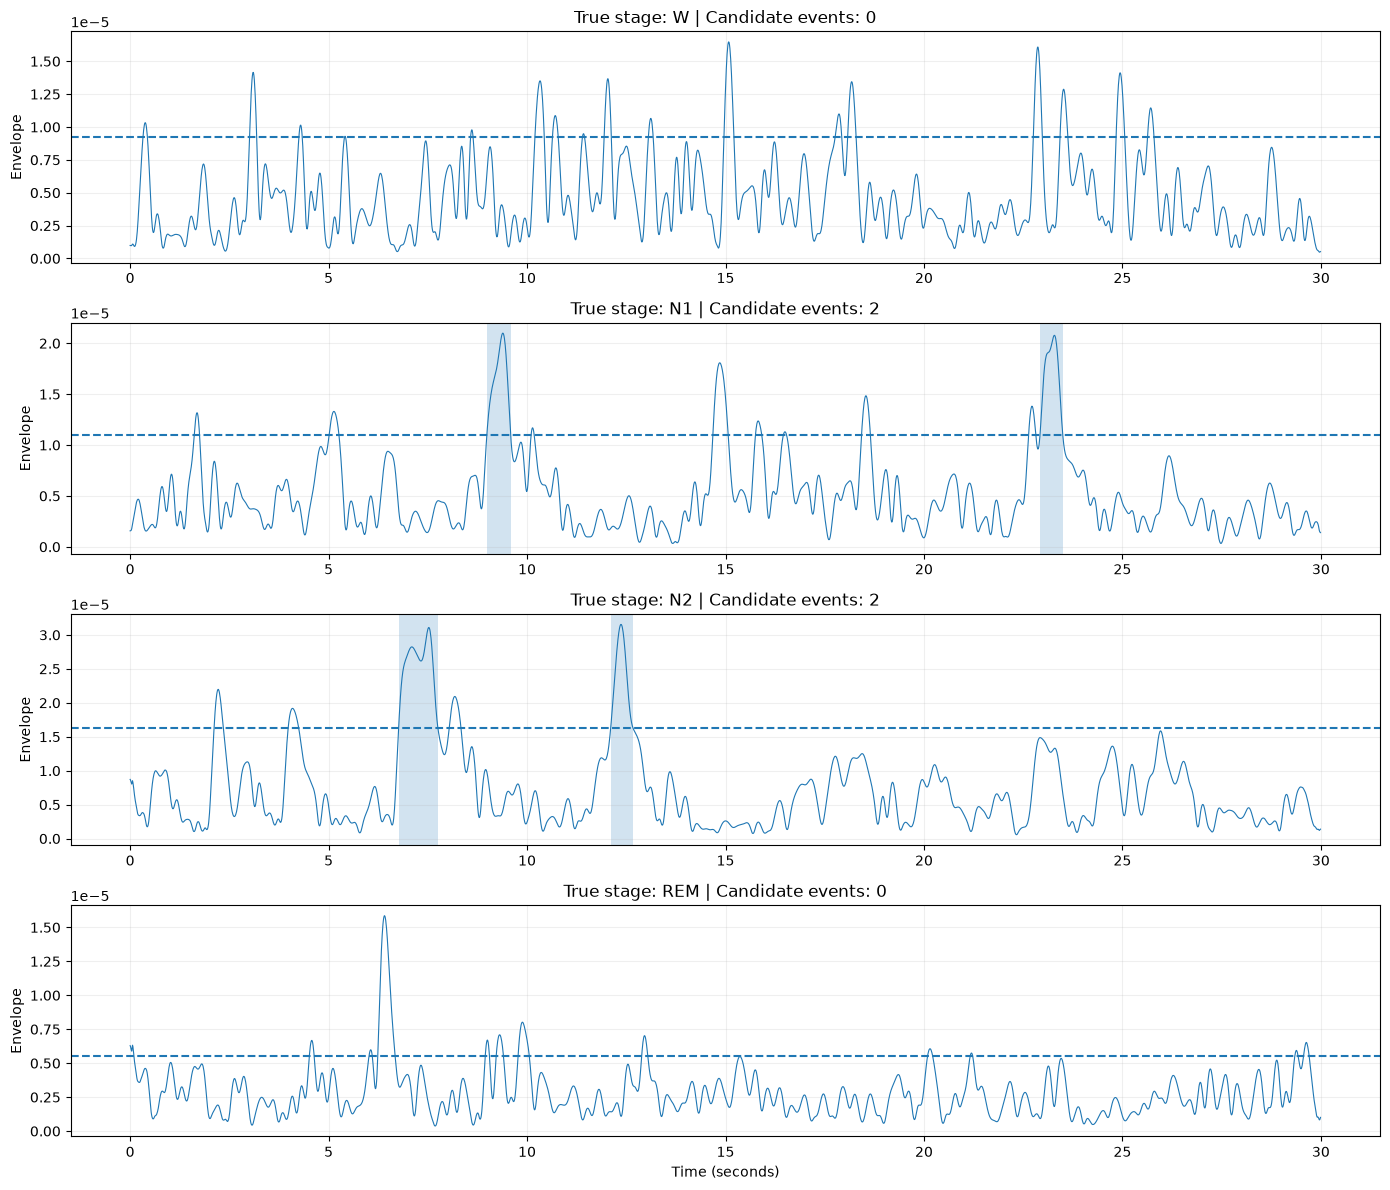

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

stage_order = ["W", "N1", "N2", "REM"]

fig, axes = plt.subplots(
    len(stage_order), 1,
    figsize=(14, 12),
)

sfreq = raw.info["sfreq"]

for ax, stage in zip(axes, stage_order):
    rows = epoch_table[epoch_table["stage"] == stage]

    if rows.empty:
        ax.set_title(f"{stage}: no epochs available")
        continue

    # Use a reproducible sample rather than always selecting the first epoch.
    epoch = rows.sample(n=1, random_state=42).iloc[0]

    start = int(round(epoch["start_sec"] * sfreq))
    end = int(round(epoch["end_sec"] * sfreq))

    signal = raw.get_data(
        picks=["EEG Fpz-Cz"],
        start=start,
        stop=end,
    )[0]

    events, filtered, envelope, threshold = detect_spindles_in_epoch(
        signal,
        sfreq,
    )

    time = np.arange(len(signal)) / sfreq

    ax.plot(time, envelope, linewidth=0.8)
    ax.axhline(threshold, linestyle="--")
    for event in events:
        ax.axvspan(
            event["start_sec"],
            event["end_sec"],
            alpha=0.2,
        )

    ax.set_title(
        f"True stage: {stage} | Candidate events: {len(events)}"
    )
    ax.set_ylabel("Envelope")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

stage_order = ["W", "N1", "N2", "REM"]
sfreq = raw.info["sfreq"]

candidate_rows = []

for stage in stage_order:
    rows = epoch_table[epoch_table["stage"] == stage]
    if rows.empty:
        continue

    epoch = rows.sample(n=1, random_state=42).iloc[0]

    start = int(round(epoch["start_sec"] * sfreq))
    end = int(round(epoch["end_sec"] * sfreq))

    signal = raw.get_data(
        picks=["EEG Fpz-Cz"],
        start=start,
        stop=end,
    )[0]

    events, filtered, envelope, threshold = (
        detect_spindles_in_epoch(signal, sfreq)
    )

    for event in events:
        candidate_rows.append({
            "stage": stage,
            "epoch_start_sec": epoch["start_sec"],
            **event,
        })

candidates_df = pd.DataFrame(candidate_rows)

if candidates_df.empty:
    print("No candidate events detected.")
else:
    display(candidates_df.round(3))

,stage,epoch_start_sec,start_sec,end_sec,duration_sec,peak_envelope
0,N1,47550.0,8.99,9.59,0.60,0.0
1,N1,47550.0,22.93,23.50,0.57,0.0
2,N2,46260.0,6.77,7.76,0.99,0.0
3,N2,46260.0,12.11,12.67,0.56,0.0


In [53]:
pd.set_option("display.float_format", lambda x: f"{x:.8e}")

display(candidates_df)

,stage,epoch_start_sec,start_sec,end_sec,duration_sec,peak_envelope
0,N1,4.75500000e+04,8.99000000e+00,9.59000000e+00,6.00000000e-01,2.09963497e-05
1,N1,4.75500000e+04,2.29300000e+01,2.35000000e+01,5.70000000e-01,2.07789769e-05
2,N2,4.62600000e+04,6.77000000e+00,7.76000000e+00,9.90000000e-01,3.10836552e-05
3,N2,4.62600000e+04,1.21100000e+01,1.26700000e+01,5.60000000e-01,3.15476253e-05


In [54]:
print("Candidate count:", len(candidates_df))
print("\nDuration statistics:")
print(candidates_df["duration_sec"].describe())

print("\nPeak-envelope statistics:")
print(candidates_df["peak_envelope"].describe())

assert np.isfinite(
    candidates_df[["duration_sec", "peak_envelope"]].to_numpy()
).all()

Candidate count: 4

Duration statistics:
count   4.00000000e+00
mean    6.80000000e-01
std     2.07364414e-01
min     5.60000000e-01
25%     5.67500000e-01
50%     5.85000000e-01
75%     6.97500000e-01
max     9.90000000e-01
Name: duration_sec, dtype: float64

Peak-envelope statistics:
count   4.00000000e+00
mean    2.61016518e-05
std     6.02422784e-06
min     2.07789769e-05
25%     2.09420065e-05
50%     2.60400024e-05
75%     3.11996477e-05
max     3.15476253e-05
Name: peak_envelope, dtype: float64


In [5]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

# --------------------------------------------------
# 1. Locate and load the SAVED V2 feature dataset
# --------------------------------------------------
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATASET_V2_PATH = (
    PROJECT_ROOT / "data" / "processed" / "sleep_epochs_v2.csv"
)

if not DATASET_V2_PATH.exists():
    raise FileNotFoundError(
        f"V2 dataset not found at: {DATASET_V2_PATH}\n"
        "Check that sleep_epochs_v2.csv exists in data/processed."
    )

dataset_v2 = pd.read_csv(DATASET_V2_PATH)

metadata_cols = [
    "subject_id",
    "recording_id",
    "epoch_index",
    "start_sec",
    "end_sec",
    "stage",
]

feature_cols_v2 = [
    col for col in dataset_v2.columns
    if col not in metadata_cols
]

X_v2 = dataset_v2[feature_cols_v2]
y_v2 = dataset_v2["stage"]
groups_v2 = dataset_v2["subject_id"]

print("Dataset shape:", dataset_v2.shape)
print("Subjects:", groups_v2.nunique())
print("Features:", len(feature_cols_v2))

# --------------------------------------------------
# 2. Recreate the subject-level train/test split
# --------------------------------------------------
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx_v2, test_idx_v2 = next(
    splitter.split(X_v2, y_v2, groups=groups_v2)
)

X_train_v2 = X_v2.iloc[train_idx_v2]
X_test_v2 = X_v2.iloc[test_idx_v2]

y_train_v2 = y_v2.iloc[train_idx_v2]
y_test_v2 = y_v2.iloc[test_idx_v2]

train_subjects_v2 = set(groups_v2.iloc[train_idx_v2])
test_subjects_v2 = set(groups_v2.iloc[test_idx_v2])

assert train_subjects_v2.isdisjoint(test_subjects_v2)

print("Training subjects:", len(train_subjects_v2))
print("Testing subjects:", len(test_subjects_v2))
print("Subject overlap:", train_subjects_v2 & test_subjects_v2)

# --------------------------------------------------
# 3. Train V2 Logistic Regression
# --------------------------------------------------
logreg_v2 = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42,
    )),
])

logreg_v2.fit(X_train_v2, y_train_v2)

# Generate predictions
pred_v2 = logreg_v2.predict(X_test_v2)

# --------------------------------------------------
# 4. Evaluate the model
# --------------------------------------------------
print("\nV2 Logistic Regression Results")
print("-" * 35)
print(f"Accuracy:          {accuracy_score(y_test_v2, pred_v2):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test_v2, pred_v2):.4f}"
)
print(
    f"Macro F1:          "
    f"{f1_score(y_test_v2, pred_v2, average='macro', zero_division=0):.4f}"
)

# --------------------------------------------------
# 5. Create the actual vs predicted table
# --------------------------------------------------
predictions_df = dataset_v2.iloc[test_idx_v2][
    ["subject_id", "recording_id", "epoch_index", "start_sec", "end_sec"]
].copy()

predictions_df = predictions_df.reset_index(drop=True)

predictions_df["Actual Stage"] = y_test_v2.reset_index(
    drop=True
)

predictions_df["Predicted Stage"] = pred_v2

predictions_df["Correct"] = (
    predictions_df["Actual Stage"]
    == predictions_df["Predicted Stage"]
)

print("\nFirst 20 test predictions:")
display(predictions_df.head(20))

Dataset shape: (414961, 44)
Subjects: 78
Features: 38
Training subjects: 62
Testing subjects: 16
Subject overlap: set()

V2 Logistic Regression Results
-----------------------------------
Accuracy:          0.8858
Balanced accuracy: 0.6694
Macro F1:          0.6823

First 20 test predictions:


,subject_id,recording_id,epoch_index,start_sec,end_sec,Actual Stage,Predicted Stage,Correct
0,SC400,SC4001E0,0,0.0,30.0,W,W,True
1,SC400,SC4001E0,1,30.0,60.0,W,W,True
2,SC400,SC4001E0,2,60.0,90.0,W,W,True
3,SC400,SC4001E0,3,90.0,120.0,W,W,True
4,SC400,SC4001E0,4,120.0,150.0,W,W,True
5,SC400,SC4001E0,5,150.0,180.0,W,W,True
6,SC400,SC4001E0,6,180.0,210.0,W,W,True
7,SC400,SC4001E0,7,210.0,240.0,W,W,True
8,SC400,SC4001E0,8,240.0,270.0,W,W,True
9,SC400,SC4001E0,9,270.0,300.0,W,W,True


In [7]:
# Display examples from each actual sleep stage
stage_examples = pd.concat(
    [
        group.sample(
            n=min(4, len(group)),
            random_state=42
        )
        for _, group in predictions_df.groupby("Actual Stage")
    ],
    ignore_index=True
)

display(
    stage_examples[
        [
            "subject_id",
            "recording_id",
            "epoch_index",
            "Actual Stage",
            "Predicted Stage",
            "Correct",
        ]
    ].sort_values(["Actual Stage", "epoch_index"])
)

,subject_id,recording_id,epoch_index,Actual Stage,Predicted Stage,Correct
1,SC450,SC4501E0,1009,N1,W,False
3,SC467,SC4672G0,1107,N1,N2,False
2,SC400,SC4001E0,1383,N1,REM,False
0,SC410,SC4101E0,1672,N1,REM,False
4,SC434,SC4341F0,847,N2,N2,True
5,SC434,SC4342F0,1464,N2,N2,True
6,SC430,SC4301E0,1465,N2,N2,True
7,SC410,SC4102E0,1719,N2,N2,True
11,SC418,SC4181E0,984,N3,N2,False
9,SC422,SC4222E0,1144,N3,N3,True


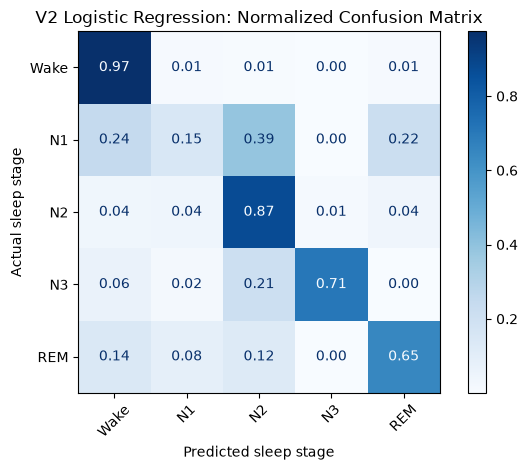

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

stage_order = ["W", "N1", "N2", "N3", "REM"]

ConfusionMatrixDisplay.from_predictions(
    y_test_v2,
    pred_v2,
    labels=stage_order,
    display_labels=["Wake", "N1", "N2", "N3", "REM"],
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)

plt.title("V2 Logistic Regression: Normalized Confusion Matrix")
plt.xlabel("Predicted sleep stage")
plt.ylabel("Actual sleep stage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

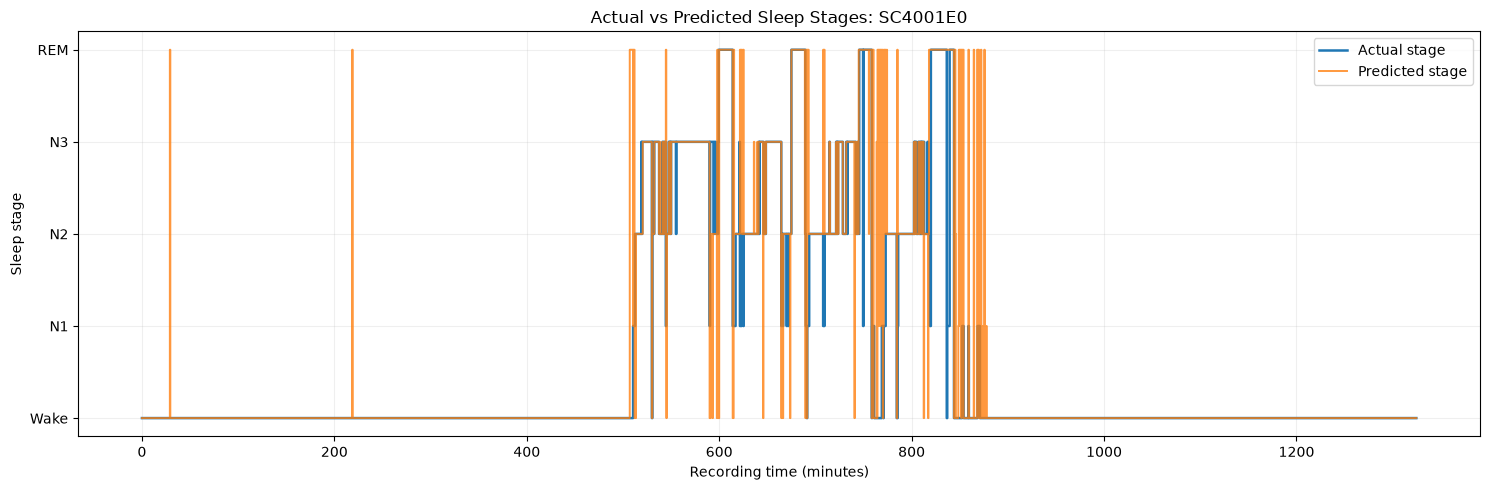

Selected recording: SC4001E0
Epochs plotted: 2650
Stage accuracy in this recording: 0.9453


In [10]:
import matplotlib.pyplot as plt

# 1. Select the test recording containing the most
#    variety of actual sleep stages.
recording_id = (
    predictions_df
    .groupby("recording_id")["Actual Stage"]
    .nunique()
    .idxmax()
)

# 2. Filter and sort its epochs chronologically.
sample = (
    predictions_df[
        predictions_df["recording_id"] == recording_id
    ]
    .sort_values("start_sec")
    .copy()
)

# 3. Map sleep stages to numeric positions for plotting.
stage_order = ["W", "N1", "N2", "N3", "REM"]

stage_to_num = {
    stage: i for i, stage in enumerate(stage_order)
}

time_minutes = sample["start_sec"] / 60

# 4. Plot actual and predicted stages.
plt.figure(figsize=(15, 5))

plt.step(
    time_minutes,
    sample["Actual Stage"].map(stage_to_num),
    where="post",
    label="Actual stage",
    linewidth=1.8,
)

plt.step(
    time_minutes,
    sample["Predicted Stage"].map(stage_to_num),
    where="post",
    label="Predicted stage",
    linewidth=1.4,
    alpha=0.8,
)

plt.yticks(
    range(5),
    ["Wake", "N1", "N2", "N3", "REM"]
)

plt.xlabel("Recording time (minutes)")
plt.ylabel("Sleep stage")
plt.title(f"Actual vs Predicted Sleep Stages: {recording_id}")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Selected recording:", recording_id)
print("Epochs plotted:", len(sample))
print(
    "Stage accuracy in this recording:",
    round(
        (
            sample["Actual Stage"] == sample["Predicted Stage"]
        ).mean(),
        4,
    ),
)

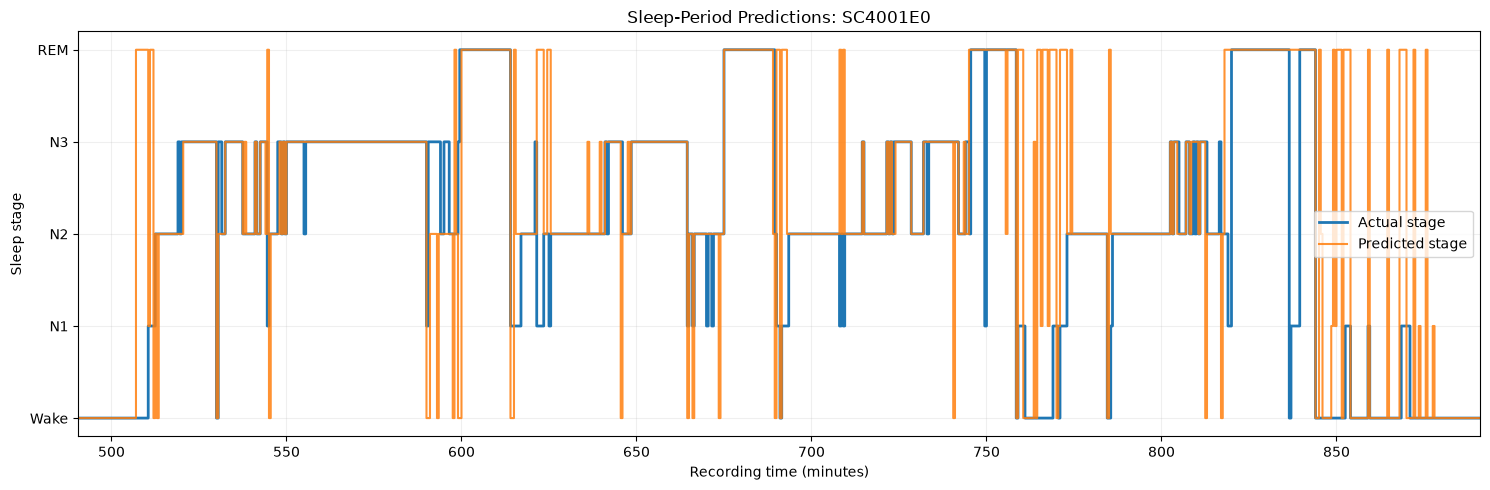

Full-recording accuracy: 0.9453
Non-Wake epoch accuracy: 0.8346
Zoomed time window: 490.5-891.0 minutes


In [11]:
import matplotlib.pyplot as plt

# Find the first and last non-Wake epochs in this recording.
sleep_rows = sample[sample["Actual Stage"] != "W"]

if sleep_rows.empty:
    raise ValueError("No non-Wake epochs found in this recording.")

sleep_start_min = sleep_rows["start_sec"].min() / 60
sleep_end_min = sleep_rows["end_sec"].max() / 60

# Include 20 minutes of context before and after sleep.
padding_min = 20

zoom_start = max(0, sleep_start_min - padding_min)
zoom_end = sleep_end_min + padding_min

zoom = sample[
    (sample["start_sec"] / 60 >= zoom_start)
    & (sample["start_sec"] / 60 <= zoom_end)
].copy()

time_minutes = zoom["start_sec"] / 60

fig, ax = plt.subplots(figsize=(15, 5))

ax.step(
    time_minutes,
    zoom["Actual Stage"].map(stage_to_num),
    where="post",
    label="Actual stage",
    linewidth=2,
)

ax.step(
    time_minutes,
    zoom["Predicted Stage"].map(stage_to_num),
    where="post",
    label="Predicted stage",
    linewidth=1.5,
    alpha=0.85,
)

ax.set_yticks(
    range(5),
    ["Wake", "N1", "N2", "N3", "REM"]
)
ax.set_xlabel("Recording time (minutes)")
ax.set_ylabel("Sleep stage")
ax.set_title(f"Sleep-Period Predictions: {recording_id}")
ax.set_xlim(zoom_start, zoom_end)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Compare overall recording accuracy with accuracy on
# epochs whose actual stage is not Wake.
print(f"Full-recording accuracy: {sample['Correct'].mean():.4f}")
print(f"Non-Wake epoch accuracy: {sleep_rows['Correct'].mean():.4f}")
print(f"Zoomed time window: {zoom_start:.1f}-{zoom_end:.1f} minutes")

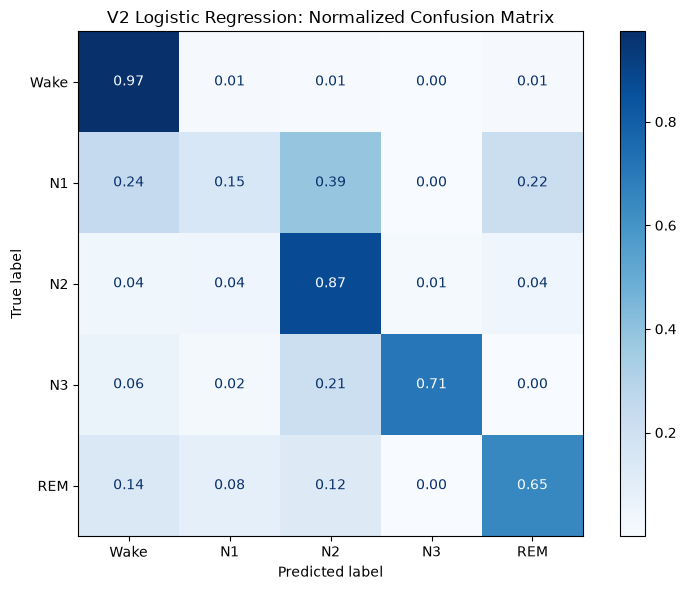

Baseline results saved to: D:\sscp\results\baseline_v2

Files created:
- classification_report.csv
- confusion_matrix.png
- summary_metrics.csv
- test_predictions.csv


In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Create an output folder in the project root.
OUTPUT_DIR = PROJECT_ROOT / "results" / "baseline_v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save epoch-level predictions.
predictions_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
)

# 2. Save per-stage precision, recall and F1.
report = classification_report(
    y_test_v2,
    pred_v2,
    labels=["W", "N1", "N2", "N3", "REM"],
    target_names=["Wake", "N1", "N2", "N3", "REM"],
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(report).T.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

# 3. Save the overall evaluation metrics.
metrics = pd.DataFrame([{
    "model": "V2 Logistic Regression",
    "accuracy": accuracy_score(y_test_v2, pred_v2),
    "balanced_accuracy": balanced_accuracy_score(
        y_test_v2, pred_v2
    ),
    "macro_f1": f1_score(
        y_test_v2, pred_v2,
        average="macro",
        zero_division=0,
    ),
    "training_subjects": len(train_subjects_v2),
    "testing_subjects": len(test_subjects_v2),
}])

metrics.to_csv(
    OUTPUT_DIR / "summary_metrics.csv",
    index=False,
)

# 4. Save the normalized confusion matrix.
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_v2,
    pred_v2,
    labels=["W", "N1", "N2", "N3", "REM"],
    display_labels=["Wake", "N1", "N2", "N3", "REM"],
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,
)

ax.set_title("V2 Logistic Regression: Normalized Confusion Matrix")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Baseline results saved to:", OUTPUT_DIR.resolve())
print("\nFiles created:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)